<img src="https://raw.githubusercontent.com/clederafael-crypto/Ciencia_Dados_Aprendizagem_Maquina/main/aprendizado-maquina-udf/assets/logo-udf.jpg" width="200">

# CRISP-DM aplicado a emissões de CO₂ e desenvolvimento dos países

**Estudante:** Cléder Rafael Narciso de Araújo (trabalho individual) · **Disciplina:** Ciência de Dados e Aprendizagem de Máquina · Profa. Kadidja Valéria · UDF 2026.2

**Pergunta do estudo:** o que o nível de desenvolvimento de um país diz sobre quanto CO₂ ele emite por pessoa, e quais países conseguem **reduzir** esse valor ao longo de uma década?

Este notebook percorre as seis fases do CRISP-DM (a documentação de cada fase está nos arquivos `00` a `07` da pasta) com dados **reais e públicos** do [Our World in Data](https://github.com/owid/co2-data) (licença CC BY 4.0), construídos a partir do Global Carbon Project, do Energy Institute e de outras fontes listadas no dicionário de dados.

**Base de dados:** um painel com **3.772 linhas** (164 países × 23 anos, de 2000 a 2022) e, derivadas dele, **2.132 janelas de 10 anos** para a classificação. A planilha `dados/planilha_base_de_dados.xlsx` descreve e traz todas essas linhas.

Três tarefas, cada uma com a pergunta que ela responde:

| Tarefa | Pergunta | Tipo | Linhas |
| --- | --- | --- | --- |
| A | Dado o perfil econômico de um país em um ano, quanto ele emite por pessoa? | Regressão | 3.772 (painel) |
| B | Com os dados de um ano, o país reduziu o CO₂ per capita nos 10 anos seguintes? | Classificação | 2.132 (janelas) |
| C | Que grupos de países existem em 2022? | Agrupamento | 163 (um corte) |

Convenção: **Resultado** (o que foi calculado), **Interpretação** e **Hipótese** (algo que os dados daqui não testam).

**Cuidado central:** como o mesmo país aparece em vários anos, o teste é feito **por país**. Se linhas do mesmo país ficassem nos dois lados, o modelo "reconheceria" o país e o resultado seria otimista.

## 0. Ambiente, versões e pastas

In [1]:
import sys, json, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.base import clone
from sklearn.model_selection import GroupKFold, StratifiedGroupKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import (mean_absolute_error, r2_score, accuracy_score, roc_auc_score,
                             confusion_matrix, recall_score, precision_score, silhouette_score, roc_curve)

SEMENTE = 42
ANO = 2022            # último ano com PIB na base
ANO_INICIO_PAINEL = 2000   # o painel vai de 2000 a 2022
JANELA = 10           # a pergunta de mudança olha 10 anos à frente

try:
    RAIZ = Path(__file__).resolve().parent.parent
except NameError:                      # dentro do notebook (pasta notebooks/)
    RAIZ = Path('..').resolve()
BRUTOS, TRATADOS = RAIZ / 'dados' / 'brutos', RAIZ / 'dados' / 'tratados'
RESULT, FIGS = RAIZ / 'resultados', RAIZ / 'figuras'
for p in (BRUTOS, TRATADOS, RESULT, FIGS):
    p.mkdir(parents=True, exist_ok=True)

URL = 'https://raw.githubusercontent.com/owid/co2-data/master/owid-co2-data.csv'
CSV = BRUTOS / 'owid-co2-data.csv'
if not CSV.exists():                   # Colab: baixa o arquivo original
    import urllib.request
    urllib.request.urlretrieve(URL, CSV)

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .25, 'font.size': 10})
AZUL, LARANJA, CINZA = '#1f5f8b', '#d9822b', '#8a8f98'
print('Python', sys.version.split()[0], '| numpy', np.__version__, '| pandas', pd.__version__,
      '| scikit-learn', sklearn.__version__, '| matplotlib', matplotlib.__version__)
R = {'versoes': {'python': sys.version.split()[0], 'numpy': np.__version__, 'pandas': pd.__version__,
                 'sklearn': sklearn.__version__, 'matplotlib': matplotlib.__version__},
     'semente': SEMENTE, 'ano_fim': ANO, 'ano_inicio_painel': ANO_INICIO_PAINEL, 'janela_anos': JANELA}

Python 3.13.18 | numpy 2.5.3 | pandas 3.0.5 | scikit-learn 1.9.1 | matplotlib 3.11.2


**Resultado.** As versões acima e a semente 42 valem para todo o notebook. O arquivo bruto é lido de `dados/brutos/` (e baixado do GitHub do OWID se estiver no Colab).

## Fase 2 — entendimento dos dados

In [2]:
bruto = pd.read_csv(CSV)
R['sha256_bruto'] = hashlib.sha256(CSV.read_bytes()).hexdigest()
agregados = bruto[bruto['iso_code'].isna() | bruto['iso_code'].astype(str).str.startswith('OWID')]
paises = bruto[~bruto.index.isin(agregados.index)].copy()
print('Linhas brutas:', bruto.shape, '| países (com código ISO):', paises['country'].nunique(),
      '| agregados/regiões descartados:', agregados['country'].nunique())
print('Anos:', bruto['year'].min(), 'a', bruto['year'].max())
R['dados'] = {'linhas': int(len(bruto)), 'colunas': int(bruto.shape[1]),
              'paises': int(paises['country'].nunique()), 'agregados': int(agregados['country'].nunique())}

cols = ['co2_per_capita', 'gdp', 'population', 'energy_per_capita', 'methane_per_capita',
        'land_use_change_co2_per_capita', 'coal_co2', 'oil_co2', 'gas_co2']
corte = paises[paises['year'] == ANO]
cobertura = (1 - corte[cols].isna().mean()).mul(100).round(1)
print(f'\nCobertura (% de países com valor) em {ANO}:'); print(cobertura.to_string())
R['cobertura_2022'] = cobertura.to_dict()
R['paises_em_2022'] = int(len(corte))

Linhas brutas: (56269, 79) | países (com código ISO): 223 | agregados/regiões descartados: 36
Anos: 1750 a 2025

Cobertura (% de países com valor) em 2022:
co2_per_capita                    97.8
gdp                               73.5
population                        99.1
energy_per_capita                 93.3
methane_per_capita                89.2
land_use_change_co2_per_capita    87.0
coal_co2                          62.3
oil_co2                           97.8
gas_co2                           58.3


**Resultado.** A base original tem 56.269 linhas e 79 colunas, de 1750 a 2025, com 259 entidades: 223 países com código ISO e 36 agregados (regiões, "Mundo", União Europeia etc.). Em 2022, 218 países têm CO₂ per capita, mas só 73,5% têm PIB (164 países). Energia (93,3%) e metano (89,2%) têm cobertura melhor; carvão (62,3%) e gás (58,3%) têm baixa.

**Interpretação.**
- Descarto os agregados para não contar a mesma emissão duas vezes.
- O PIB é o gargalo: limita a análise a 164 países, e a base não tem PIB depois de 2022.

**Hipótese.** As ausências em carvão e gás podem significar "zero" (o país não usa o combustível) em vez de "não medido". Os dados não permitem separar as duas coisas.

## Fase 3 — preparação: o painel país-ano

In [3]:
def prepara(df):
    d = df.copy()
    d['pib_per_capita'] = d['gdp'] / d['population']                # US$ internacionais de 2011
    d['part_carvao'] = d['coal_co2'] / d['co2']
    d['part_petroleo'] = d['oil_co2'] / d['co2']
    d['part_gas'] = d['gas_co2'] / d['co2']
    d = d.rename(columns={'country': 'pais', 'year': 'ano', 'population': 'populacao',
                          'energy_per_capita': 'energia_per_capita', 'methane_per_capita': 'metano_per_capita'})
    return d[['iso_code', 'pais', 'ano', 'populacao', 'pib_per_capita', 'co2_per_capita', 'energia_per_capita',
              'metano_per_capita', 'part_carvao', 'part_petroleo', 'part_gas']]

todos_anos = prepara(paises)
P = (todos_anos[todos_anos['ano'].between(ANO_INICIO_PAINEL, ANO)]
     .dropna(subset=['co2_per_capita', 'pib_per_capita', 'populacao']).query('co2_per_capita > 0').copy())
P['log_co2'] = np.log10(P['co2_per_capita'])
P['log_pib'] = np.log10(P['pib_per_capita'])
P['log_pop'] = np.log10(P['populacao'])
P['log_energia'] = np.log10(P['energia_per_capita'].where(P['energia_per_capita'] > 0))
P = P.reset_index(drop=True)
print('PAINEL país-ano:', len(P), 'linhas |', P['iso_code'].nunique(), 'países |', P['ano'].min(), 'a', P['ano'].max())
print('Linhas por país (mín/mediana/máx):', P.groupby('iso_code').size().agg(['min', 'median', 'max']).tolist())
print('Ausências nas colunas usadas:'); print(P[['log_energia', 'metano_per_capita', 'part_carvao', 'part_petroleo', 'part_gas']].isna().sum().to_string())
R['painel'] = {'linhas': int(len(P)), 'paises': int(P['iso_code'].nunique()), 'ano_min': int(P['ano'].min()), 'ano_max': int(P['ano'].max()),
               'linhas_por_pais': P.groupby('iso_code').size().agg(['min', 'median', 'max']).astype(int).tolist(),
               'ausentes': P[['log_energia', 'metano_per_capita', 'part_carvao', 'part_petroleo', 'part_gas']].isna().sum().astype(int).to_dict()}

# janelas de 10 anos: atributos no ano inicial, alvo no ano final (só para a classificação)
co2_serie = paises.set_index(['iso_code', 'year'])['co2_per_capita']
def co2_em(anos):
    idx = pd.MultiIndex.from_arrays([P['iso_code'], P['ano'] + anos])
    return co2_serie.reindex(idx).values
J = P[P['ano'] <= ANO - JANELA].copy()
J['ano_final'] = J['ano'] + JANELA
J['co2_final'] = co2_em(JANELA)[J.index]
J['co2_5_anos_antes'] = co2_em(-5)[J.index]
J = J[J['co2_final'] > 0].copy()
J['reduziu'] = (J['co2_final'] < J['co2_per_capita']).astype(int)
J['variacao_pct'] = (J['co2_final'] / J['co2_per_capita'] - 1) * 100
J['tendencia_5a'] = J['log_co2'] - np.log10(J['co2_5_anos_antes'].where(J['co2_5_anos_antes'] > 0))
J = J.reset_index(drop=True)
print('\nJANELAS de 10 anos:', len(J), 'linhas |', J['iso_code'].nunique(), 'países | anos iniciais', J['ano'].min(), 'a', J['ano'].max())
print('Reduziram:', int(J['reduziu'].sum()), f"({J['reduziu'].mean():.1%}) | não reduziram: {int((1 - J['reduziu']).sum())}")
R['janelas'] = {'linhas': int(len(J)), 'paises': int(J['iso_code'].nunique()), 'reduziram': int(J['reduziu'].sum()),
                'prop_reduziu': float(J['reduziu'].mean())}

# separação por PAÍS (um país nunca fica nos dois lados), feita antes de qualquer ajuste
isos = np.array(sorted(P['iso_code'].unique()))
teste_isos = set(np.random.default_rng(SEMENTE).choice(isos, size=int(round(0.25 * len(isos))), replace=False))
P['conjunto'] = np.where(P['iso_code'].isin(teste_isos), 'teste', 'treino')
J['conjunto'] = np.where(J['iso_code'].isin(teste_isos), 'teste', 'treino')
print('\nPaíses de teste:', len(teste_isos), '| países de treino:', len(isos) - len(teste_isos))
print('Painel — treino:', int((P.conjunto == 'treino').sum()), 'linhas | teste:', int((P.conjunto == 'teste').sum()), 'linhas')
print('Janelas — treino:', int((J.conjunto == 'treino').sum()), 'linhas | teste:', int((J.conjunto == 'teste').sum()), 'linhas')
R['separacao'] = {'paises_teste': len(teste_isos), 'paises_treino': int(len(isos) - len(teste_isos)),
                  'painel_treino': int((P.conjunto == 'treino').sum()), 'painel_teste': int((P.conjunto == 'teste').sum()),
                  'janelas_treino': int((J.conjunto == 'treino').sum()), 'janelas_teste': int((J.conjunto == 'teste').sum()),
                  'brasil_no': 'teste' if 'BRA' in teste_isos else 'treino'}
P.to_csv(TRATADOS / 'painel_pais_ano.csv', index=False); J.to_csv(TRATADOS / 'janelas_10_anos.csv', index=False)

PAINEL país-ano: 3772 linhas | 164 países | 2000 a 2022
Linhas por país (mín/mediana/máx): [23.0, 23.0, 23.0]
Ausências nas colunas usadas:
log_energia            12
metano_per_capita      23
part_carvao           865
part_petroleo           0
part_gas             1122

JANELAS de 10 anos: 2132 linhas | 164 países | anos iniciais 2000 a 2012
Reduziram: 898 (42.1%) | não reduziram: 1234

Países de teste: 41 | países de treino: 123
Painel — treino: 2829 linhas | teste: 943 linhas
Janelas — treino: 1599 linhas | teste: 533 linhas


**Resultado.**
- **Painel:** 3.772 linhas, 164 países, 2000 a 2022, com 23 anos para cada país (painel balanceado). Ausências nas colunas usadas: energia 12, metano 23, participação do carvão 865 e do gás 1.122 (o petróleo, nenhuma).
- **Janelas de 10 anos:** 2.132 linhas (anos iniciais de 2000 a 2012, 13 por país). Em 898 delas (42,1%) o CO₂ per capita caiu em 10 anos.
- **Separação por país:** 41 países de teste (943 linhas do painel e 533 janelas) e 123 de treino (2.829 linhas e 1.599 janelas).

**Interpretação.**
- O alvo é o logaritmo do CO₂ per capita, e uso o log do PIB per capita, da população e da energia, porque as distribuições são muito assimétricas.
- A imputação de ausências é a **mediana, dentro do `Pipeline`**, aprendida só no treino.
- Na classificação, os atributos são do ano inicial (ou anteriores), e o alvo é do ano final. Não há informação do futuro nos atributos.
- O sorteio dos 41 países de teste foi feito uma vez, com semente, antes de qualquer ajuste. **O Brasil caiu no treino.** Por isso, na análise do Brasil, uso um modelo ajustado sem ele.

**Cuidado.** As 13 janelas de um mesmo país se sobrepõem (cada uma compartilha 9 anos com a vizinha). O número efetivo de observações independentes é mais próximo de 164 países do que de 2.132 linhas.

## Figura 1 — visão geral dos dados

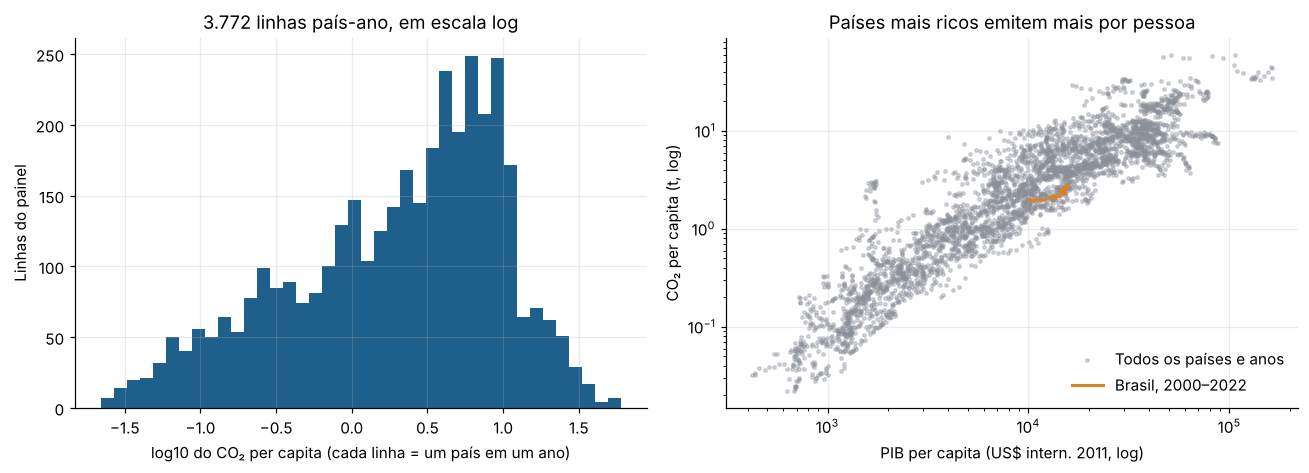

Correlação entre log PIB per capita e log CO2 per capita (todas as linhas): 0.925


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
ax[0].hist(P['log_co2'], bins=40, color=AZUL); ax[0].set_xlabel('log10 do CO₂ per capita (cada linha = um país em um ano)')
ax[0].set_ylabel('Linhas do painel'); ax[0].set_title(f'{len(P):,}'.replace(',', '.') + ' linhas país-ano, em escala log')
ax[1].scatter(P['pib_per_capita'], P['co2_per_capita'], s=5, color=CINZA, alpha=.35, label='Todos os países e anos')
brp = P[P['iso_code'] == 'BRA'].sort_values('ano')
ax[1].plot(brp['pib_per_capita'], brp['co2_per_capita'], color=LARANJA, lw=2, label='Brasil, 2000–2022')
ax[1].set_xscale('log'); ax[1].set_yscale('log'); ax[1].set_xlabel('PIB per capita (US$ intern. 2011, log)')
ax[1].set_ylabel('CO₂ per capita (t, log)'); ax[1].set_title('Países mais ricos emitem mais por pessoa'); ax[1].legend(frameon=False, loc='lower right')
plt.tight_layout(); plt.savefig(FIGS / '01-visao-geral.png', dpi=130); plt.show()
r_log = float(np.corrcoef(P.log_pib, P.log_co2)[0, 1])
print('Correlação entre log PIB per capita e log CO2 per capita (todas as linhas):', round(r_log, 3))
R['correlacao_log_pib_log_co2'] = r_log

**Resultado.** A correlação entre o log do PIB per capita e o log do CO₂ per capita, em todas as linhas, é 0,925.

**Interpretação.** Em escala log, a distribuição das 3.772 linhas é regular, e a nuvem de PIB × CO₂ é aproximadamente uma reta: países mais ricos emitem mais por pessoa. A trajetória do Brasil (laranja) sobe junto com o PIB entre 2000 e 2014 e depois recua.

**Hipótese.** A correlação é alta, mas não indica causa: países ricos têm também mais indústria, transporte e consumo de energia.

## Fase 4A — regressão: quanto um país emite por pessoa, dado seu perfil?

In [5]:
conjuntos = {'1 só PIB per capita': ['log_pib'],
             '2 PIB + população + metano + ano': ['log_pib', 'log_pop', 'metano_per_capita', 'ano'],
             '3 PIB + pop. + metano + ano + energia': ['log_pib', 'log_pop', 'metano_per_capita', 'ano', 'log_energia']}
tr = P[P.conjunto == 'treino'].reset_index(drop=True); te = P[P.conjunto == 'teste'].reset_index(drop=True)
print('Treino:', len(tr), 'linhas de', tr.iso_code.nunique(), 'países | Teste:', len(te), 'linhas de', te.iso_code.nunique(), 'países')

def divisoes_regressao(g, reps=3, k=5):
    out = []
    for r in range(reps):
        out += list(GroupKFold(n_splits=k, shuffle=True, random_state=SEMENTE + r).split(np.zeros(len(g)), groups=g))
    return out
cvr = divisoes_regressao(tr['iso_code'])

def pipe_reg(modelo):
    etapas = [('imp', SimpleImputer(strategy='median'))]
    if isinstance(modelo, LinearRegression):
        etapas.append(('esc', StandardScaler()))
    return Pipeline(etapas + [('m', modelo)])

def modelos():
    return {'Linear': LinearRegression(),
            'Floresta': RandomForestRegressor(n_estimators=150, min_samples_leaf=5, random_state=SEMENTE, n_jobs=1)}

linhas = []
for nome, cs in conjuntos.items():
    for mn, m in modelos().items():
        s = cross_validate(pipe_reg(m), tr[cs], tr['log_co2'], cv=cvr, scoring={'mae': 'neg_mean_absolute_error', 'r2': 'r2'})
        linhas.append({'conjunto': nome, 'modelo': mn, 'mae_val': -s['test_mae'].mean(),
                       'mae_desvio': s['test_mae'].std(), 'r2_val': s['test_r2'].mean()})
base = cross_validate(Pipeline([('m', DummyRegressor())]), tr[['log_pib']], tr['log_co2'], cv=cvr,
                      scoring={'mae': 'neg_mean_absolute_error', 'r2': 'r2'})
linhas.append({'conjunto': 'referência (média)', 'modelo': 'Dummy', 'mae_val': -base['test_mae'].mean(),
               'mae_desvio': base['test_mae'].std(), 'r2_val': base['test_r2'].mean()})
reg_cv = pd.DataFrame(linhas)
print(reg_cv.round(4).to_string(index=False))
reg_cv.round(4).to_csv(RESULT / 'regressao_validacao.csv', index=False)
melhor = reg_cv[reg_cv.modelo != 'Dummy'].sort_values('mae_val', kind='stable').iloc[0]     # regra: menor MAE médio de validação
print('\nEscolhido pela validação:', melhor['conjunto'], '+', melhor['modelo'])

Treino: 2829 linhas de 123 países | Teste: 943 linhas de 41 países


                             conjunto   modelo  mae_val  mae_desvio  r2_val
                  1 só PIB per capita   Linear   0.2171      0.0312  0.8317
                  1 só PIB per capita Floresta   0.2318      0.0225  0.8064
     2 PIB + população + metano + ano   Linear   0.2113      0.0304  0.8389
     2 PIB + população + metano + ano Floresta   0.2315      0.0233  0.7982
3 PIB + pop. + metano + ano + energia   Linear   0.1107      0.0139  0.9485
3 PIB + pop. + metano + ano + energia Floresta   0.1276      0.0157  0.9367
                   referência (média)    Dummy   0.5724      0.0800 -0.0317

Escolhido pela validação: 3 PIB + pop. + metano + ano + energia + Linear


**Resultado.** Na validação cruzada repetida **por país** (5 partes × 3 repetições, só no treino de 2.829 linhas):

| Conjunto de atributos | Modelo | MAE em log10 | Erro típico | R² |
| --- | --- | --- | --- | --- |
| Só PIB per capita | Linear | 0,2171 | ×1,65 | 0,83 |
| PIB + população + metano + ano | Linear | 0,2113 | ×1,63 | 0,84 |
| PIB + população + metano + ano + energia | Linear | **0,1107** | **×1,29** | **0,95** |
| Referência (prever a média) | — | 0,5724 | ×3,74 | −0,03 |

A regressão linear ficou à frente da floresta aleatória nos três conjuntos, por margens de 0,015 a 0,020 de MAE, do tamanho do desvio entre as partes (0,014 a 0,031). Pela regra fixada antes de olhar o teste (menor MAE médio de validação), o escolhido é **conjunto 3 + modelo linear**.

**Interpretação.**
- População, metano e ano quase não ajudam (0,2171 → 0,2113). O ganho vem da **energia per capita**, que reduz o erro típico de ×1,65 para ×1,29.
- Isso faz sentido e é quase mecânico: CO₂ vem da queima de combustíveis, e a energia consumida mede essa queima. O modelo 3 prevê bem, mas diz menos sobre *desenvolvimento* do que o modelo 1.

**Hipótese.** O que sobra depois da energia deve refletir a **composição da matriz energética** (hidrelétrica e geotérmica emitem pouco; carvão emite muito). Essa variável não está no modelo, e eu não a testei.

## Fase 5A — avaliação final da regressão (países de teste, usados uma única vez)

MAE (log10) teste: 0.0901 → erro típico de ×1.23 | referência: 0.5915 (×3.90)
R² teste: 0.9667

Descritivo (teste por conjunto, mesmo modelo):
                                          mae      r2
1 só PIB per capita                    0.1805  0.8914
2 PIB + população + metano + ano       0.1726  0.9006
3 PIB + pop. + metano + ano + energia  0.0901  0.9667


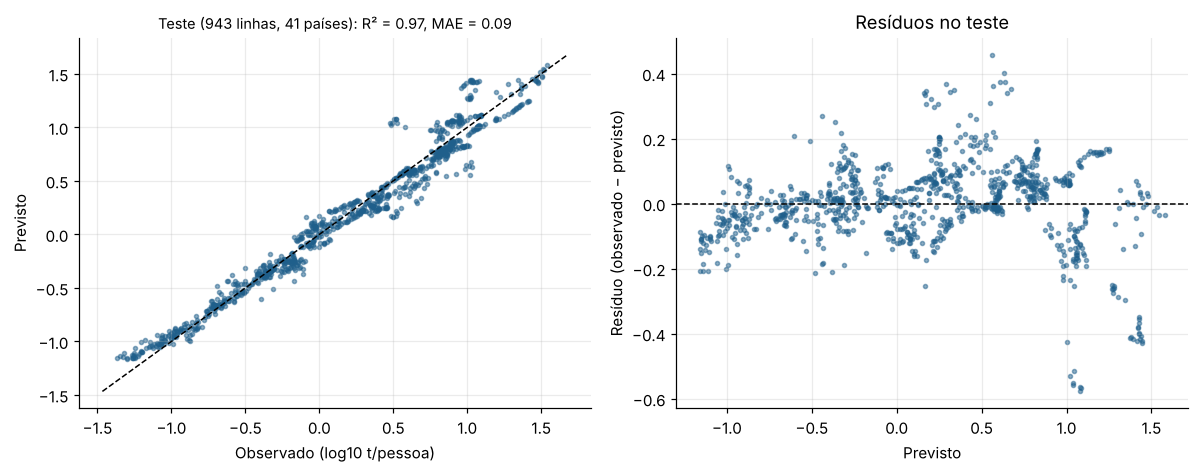

Resíduos: média 0.002, desvio 0.127

Teste — emitem mais que o previsto (resíduo médio 2000–2022):
iso_code        pais  linhas  residuo_medio
     MNG    Mongolia      23          0.324
     IRQ        Iraq      23          0.165
     LCA Saint Lucia      23          0.155
     LUX  Luxembourg      23          0.140
     ISR      Israel      23          0.123
Teste — emitem menos que o previsto:
iso_code        pais  linhas  residuo_medio
     ISL     Iceland      23         -0.353
     MLT       Malta      23         -0.283
     NZL New Zealand      23         -0.158
     PRY    Paraguay      23         -0.122
     NER       Niger      23         -0.120

Brasil (previsto por um modelo sem o Brasil): {'no_conjunto': 'treino', 'residuo_medio_log10': -0.205, 'fator_medio': 0.624, 'co2_2022': 2.285, 'previsto_2022_t': 3.961, 'anos_abaixo_do_previsto': 23, 'anos': 23}


In [6]:
cs_final = conjuntos[melhor['conjunto']]
modelo_reg = pipe_reg(modelos()[melhor['modelo']]).fit(tr[cs_final], tr['log_co2'])
pred = modelo_reg.predict(te[cs_final])
dummy = Pipeline([('m', DummyRegressor())]).fit(tr[['log_pib']], tr['log_co2'])
mae_te, r2_te = mean_absolute_error(te['log_co2'], pred), r2_score(te['log_co2'], pred)
mae_ref = mean_absolute_error(te['log_co2'], dummy.predict(te[['log_pib']]))
print(f'MAE (log10) teste: {mae_te:.4f} → erro típico de ×{10 ** mae_te:.2f} | referência: {mae_ref:.4f} (×{10 ** mae_ref:.2f})')
print(f'R² teste: {r2_te:.4f}')
R['regressao'] = {'conjunto': melhor['conjunto'], 'modelo': melhor['modelo'], 'n_treino': int(len(tr)), 'n_teste': int(len(te)),
                  'mae_log10': float(mae_te), 'fator_erro': float(10 ** mae_te), 'r2_teste': float(r2_te),
                  'mae_referencia_log10': float(mae_ref), 'fator_erro_referencia': float(10 ** mae_ref),
                  'validacao': reg_cv.round(4).to_dict('records')}
extra = {}
for nome, cs in conjuntos.items():      # descritivo: já conhecido o teste, não altera a escolha
    m = pipe_reg(modelos()[melhor['modelo']]).fit(tr[cs], tr['log_co2'])
    extra[nome] = {'mae': float(mean_absolute_error(te['log_co2'], m.predict(te[cs]))), 'r2': float(r2_score(te['log_co2'], m.predict(te[cs])))}
R['regressao']['teste_por_conjunto_descritivo'] = extra
print('\nDescritivo (teste por conjunto, mesmo modelo):'); print(pd.DataFrame(extra).T.round(4).to_string())

res = te['log_co2'] - pred
fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
ax[0].scatter(te['log_co2'], pred, s=7, color=AZUL, alpha=.5)
lim = [min(te['log_co2'].min(), pred.min()) - .1, max(te['log_co2'].max(), pred.max()) + .1]
ax[0].plot(lim, lim, '--', color='black', lw=1); ax[0].set_xlabel('Observado (log10 t/pessoa)')
ax[0].set_ylabel('Previsto'); ax[0].set_title(f'Teste ({len(te)} linhas, {te.iso_code.nunique()} países): R² = {r2_te:.2f}, MAE = {mae_te:.2f}', fontsize=9.5)
ax[1].scatter(pred, res, s=7, color=AZUL, alpha=.5); ax[1].axhline(0, color='black', ls='--', lw=1)
ax[1].set_xlabel('Previsto'); ax[1].set_ylabel('Resíduo (observado − previsto)'); ax[1].set_title('Resíduos no teste')
plt.tight_layout(); plt.savefig(FIGS / '02-regressao.png', dpi=130); plt.show()
print(f'Resíduos: média {res.mean():.3f}, desvio {res.std():.3f}')
te = te.assign(previsto=pred, residuo=res)
por_pais = te.groupby(['iso_code', 'pais']).agg(linhas=('ano', 'size'), residuo_medio=('residuo', 'mean')).reset_index()
R['regressao']['teste_acima_previsto'] = por_pais.nlargest(5, 'residuo_medio').round(3).to_dict('records')
R['regressao']['teste_abaixo_previsto'] = por_pais.nsmallest(5, 'residuo_medio').round(3).to_dict('records')
print('\nTeste — emitem mais que o previsto (resíduo médio 2000–2022):'); print(por_pais.nlargest(5, 'residuo_medio').round(3).to_string(index=False))
print('Teste — emitem menos que o previsto:'); print(por_pais.nsmallest(5, 'residuo_medio').round(3).to_string(index=False))
# O Brasil caiu no treino. Para uma comparação honesta, prevejo o Brasil com um modelo ajustado SEM o Brasil.
sem_br = tr[tr.iso_code != 'BRA']
m_br = pipe_reg(modelos()[melhor['modelo']]).fit(sem_br[cs_final], sem_br['log_co2'])
bra = P[P.iso_code == 'BRA'].sort_values('ano').copy()
bra['previsto'] = m_br.predict(bra[cs_final]); bra['residuo'] = bra['log_co2'] - bra['previsto']
r22 = bra[bra.ano == ANO].iloc[0]
R['brasil_regressao'] = {'no_conjunto': R['separacao']['brasil_no'], 'residuo_medio_log10': float(bra['residuo'].mean()),
                         'fator_medio': float(10 ** bra['residuo'].mean()), 'co2_2022': float(r22['co2_per_capita']),
                         'previsto_2022_t': float(10 ** r22['previsto']), 'anos_abaixo_do_previsto': int((bra['residuo'] < 0).sum()), 'anos': int(len(bra))}
print('\nBrasil (previsto por um modelo sem o Brasil):', {k: (round(v, 3) if isinstance(v, float) else v) for k, v in R['brasil_regressao'].items()})
te[['iso_code', 'pais', 'ano', 'co2_per_capita', 'previsto', 'residuo']].assign(previsto_t=lambda d: 10 ** d['previsto']).to_csv(TRATADOS / 'previsoes_regressao_teste.csv', index=False)

**Resultado.** No teste (943 linhas de 41 países que o modelo nunca viu): MAE de 0,0901 em log10 (erro típico de ×1,23) e R² de 0,9667. A referência tem MAE de 0,5915 (×3,90). Pelo conjunto de atributos, no mesmo teste e **só como descrição**: só PIB, R² 0,8914 (MAE 0,1805); PIB + população + metano + ano, R² 0,9006 (MAE 0,1726). Os resíduos têm média de 0,002 e desvio de 0,127.

Por país (resíduo médio em 2000–2022, em log10), os que mais **emitem acima do previsto**: Mongólia (+0,32), Iraque (+0,17), Santa Lúcia (+0,16), Luxemburgo (+0,14) e Israel (+0,12). Os que mais **emitem abaixo**: Islândia (−0,35), Malta (−0,28), Nova Zelândia (−0,16), Paraguai (−0,12) e Níger (−0,12).

**Brasil** (previsto por um modelo ajustado sem o Brasil): em 2022 emite 2,29 t/pessoa, e o modelo previu 3,96. Nos 23 anos do painel o Brasil ficou abaixo do previsto, em média cerca de 0,62 vez o valor esperado (resíduo médio de −0,205).

**Interpretação.**
- O erro típico é de cerca de 23% para mais ou para menos, contra um fator de 3,90 da referência.
- O gráfico dos resíduos (leitura visual) não mostra curva evidente. Os pontos aparecem em faixas porque o erro de um país se repete ao longo dos 23 anos. Os pontos mais negativos (até cerca de −0,6) estão entre as previsões mais altas.
- Os 41 países de teste são uma única divisão. Outro sorteio de países daria outro valor de R².

**Hipótese.** Brasil, Islândia e Paraguai têm eletricidade majoritariamente renovável, o que explicaria emitir menos do que o previsto pela energia consumida. A Mongólia usa muito carvão. Nenhuma dessas explicações foi verificada com os dados daqui.

## Fase 4B — classificação: o país reduziu o CO2 per capita nos 10 anos seguintes?

In [7]:
atrib = ['ano', 'log_co2', 'log_pib', 'log_pop', 'log_energia', 'metano_per_capita',
         'part_carvao', 'part_petroleo', 'part_gas', 'tendencia_5a']
jtr = J[J.conjunto == 'treino'].reset_index(drop=True); jte = J[J.conjunto == 'teste'].reset_index(drop=True)
print('Treino:', len(jtr), 'janelas de', jtr.iso_code.nunique(), 'países | Teste:', len(jte), 'janelas de', jte.iso_code.nunique(), 'países')
print(f'% que reduziu: treino {jtr.reduziu.mean():.3f} | teste {jte.reduziu.mean():.3f}')
cvc = []
for r in range(3):
    cvc += list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMENTE + r).split(jtr[atrib], jtr['reduziu'], groups=jtr['iso_code']))

def pipe_cls(m, escala=False):
    et = [('imp', SimpleImputer(strategy='median'))]
    if escala:
        et.append(('esc', StandardScaler()))
    return Pipeline(et + [('m', m)])

cand = {'Referência (classe mais frequente)': pipe_cls(DummyClassifier(strategy='most_frequent')),
        'Regressão logística': pipe_cls(LogisticRegression(max_iter=1000), True),
        'Árvore (prof. 4)': pipe_cls(DecisionTreeClassifier(max_depth=4, min_samples_leaf=20, random_state=SEMENTE)),
        'Floresta': pipe_cls(RandomForestClassifier(n_estimators=150, min_samples_leaf=10, random_state=SEMENTE, n_jobs=1))}
linhas = []
for nome, m in cand.items():
    s = cross_validate(m, jtr[atrib], jtr['reduziu'], cv=cvc, scoring=['accuracy', 'roc_auc'])
    linhas.append({'modelo': nome, 'acc_val': s['test_accuracy'].mean(), 'acc_desvio': s['test_accuracy'].std(),
                   'auc_val': s['test_roc_auc'].mean(), 'auc_desvio': s['test_roc_auc'].std()})
cls_cv = pd.DataFrame(linhas); print(cls_cv.round(4).to_string(index=False))
cls_cv.round(4).to_csv(RESULT / 'classificacao_validacao.csv', index=False)
melhor_c = cls_cv.iloc[1:].sort_values('auc_val', ascending=False, kind='stable').iloc[0]['modelo']   # regra: maior AUC médio
print('\nEscolhido pela validação (maior AUC médio):', melhor_c)

Treino: 1599 janelas de 123 países | Teste: 533 janelas de 41 países
% que reduziu: treino 0.450 | teste 0.334


                            modelo  acc_val  acc_desvio  auc_val  auc_desvio
Referência (classe mais frequente)   0.5497      0.0032   0.5000      0.0000
               Regressão logística   0.7163      0.0341   0.7873      0.0331
                  Árvore (prof. 4)   0.6970      0.0403   0.7306      0.0735
                          Floresta   0.7222      0.0520   0.7790      0.0604

Escolhido pela validação (maior AUC médio): Regressão logística


**Resultado.** Validação cruzada repetida por país no treino (1.599 janelas de 123 países):

| Modelo | Acurácia | AUC |
| --- | --- | --- |
| Referência (classe mais frequente) | 0,5497 ± 0,0032 | 0,5000 |
| Regressão logística | 0,7163 ± 0,0341 | **0,7873 ± 0,0331** |
| Árvore (profundidade 4) | 0,6970 ± 0,0403 | 0,7306 ± 0,0735 |
| Floresta | 0,7222 ± 0,0520 | 0,7790 ± 0,0604 |

Pela regra fixada antes (maior AUC médio), o escolhido é a **regressão logística**.

**Interpretação.** A diferença de AUC entre a logística e a floresta (0,008) é muito menor que o desvio entre as partes (0,03 a 0,06), então elas empatam na prática. Escolhi pela regra. Aqui o modelo mais simples e fácil de interpretar também é o melhor, e isso me ajuda a explicar os resultados.

## Fase 5B — avaliação final da classificação (países de teste, usados uma única vez)

Acurácia teste: 0.7842 | referência: 0.6660 | AUC: 0.8286
Matriz [linhas reais, colunas previstas] (0 = não reduziu, 1 = reduziu):
[[284  71]
 [ 44 134]]
Sensibilidade (reduziu): 0.7528 | Precisão: 0.6537


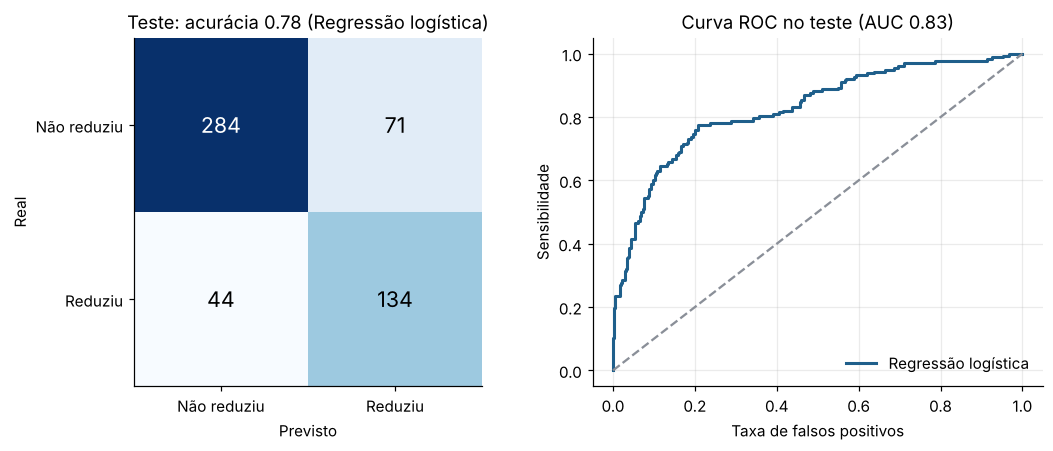


Coeficientes padronizados da logística (treino):
part_gas            -0.339
tendencia_5a        -0.335
log_pib             -0.234
part_carvao         -0.115
log_pop              0.053
part_petroleo        0.080
log_energia          0.101
metano_per_capita    0.101
ano                  0.391
log_co2              1.516

Brasil (modelo sem o Brasil): {'no_conjunto': 'treino', 'janelas': 13, 'reduziu_real': 2, 'acertos': 7}
 ano  ano_final  reduziu  previsto  prob_reduzir
2000       2010        0         0          0.38
2001       2011        0         0          0.42
2002       2012        0         0          0.45
2003       2013        0         0          0.48
2004       2014        0         0          0.50
2005       2015        0         1          0.53
2006       2016        0         1          0.55
2007       2017        0         1          0.57
2008       2018        0         1          0.57
2009       2019        0         1          0.63
2010       2020        1         1  

In [8]:
mc = cand[melhor_c].fit(jtr[atrib], jtr['reduziu'])
ref = cand['Referência (classe mais frequente)'].fit(jtr[atrib], jtr['reduziu'])
prev, prob = mc.predict(jte[atrib]), mc.predict_proba(jte[atrib])[:, 1]
yb_te = jte['reduziu']
cm = confusion_matrix(yb_te, prev, labels=[0, 1]); tn, fp, fn, tp = cm.ravel()
acc, acc_ref = accuracy_score(yb_te, prev), accuracy_score(yb_te, ref.predict(jte[atrib]))
auc = roc_auc_score(yb_te, prob)
print(f'Acurácia teste: {acc:.4f} | referência: {acc_ref:.4f} | AUC: {auc:.4f}')
print('Matriz [linhas reais, colunas previstas] (0 = não reduziu, 1 = reduziu):'); print(cm)
sens = tp / (tp + fn); prec = tp / (tp + fp) if tp + fp else float('nan')
print(f'Sensibilidade (reduziu): {sens:.4f} | Precisão: {prec:.4f}')
R['classificacao'] = {'modelo': melhor_c, 'n_treino': int(len(jtr)), 'n_teste': int(len(jte)),
                      'acuracia_teste': float(acc), 'acuracia_referencia': float(acc_ref), 'auc_teste': float(auc),
                      'matriz': cm.tolist(), 'sensibilidade': float(sens), 'precisao': float(prec),
                      'validacao': cls_cv.round(4).to_dict('records')}
fig, ax = plt.subplots(1, 2, figsize=(10, 4.2))
ax[0].imshow(cm, cmap='Blues')
for i in range(2):
    for j in range(2):
        ax[0].text(j, i, cm[i, j], ha='center', va='center', fontsize=14, color='white' if cm[i, j] > cm.max() / 2 else 'black')
ax[0].set_xticks([0, 1], ['Não reduziu', 'Reduziu']); ax[0].set_yticks([0, 1], ['Não reduziu', 'Reduziu'])
ax[0].set_xlabel('Previsto'); ax[0].set_ylabel('Real'); ax[0].set_title(f'Teste: acurácia {acc:.2f} ({melhor_c})'); ax[0].grid(False)
fpr, tpr, _ = roc_curve(yb_te, prob); ax[1].plot(fpr, tpr, color=AZUL, lw=2, label=melhor_c); ax[1].legend(frameon=False, loc='lower right')
ax[1].set_xlabel('Taxa de falsos positivos'); ax[1].set_ylabel('Sensibilidade')
ax[1].plot([0, 1], [0, 1], '--', color=CINZA); ax[1].set_title(f'Curva ROC no teste (AUC {auc:.2f})')
plt.tight_layout(); plt.savefig(FIGS / '03-classificacao.png', dpi=130); plt.show()

lr = cand['Regressão logística'].fit(jtr[atrib], jtr['reduziu'])
coef = pd.Series(lr.named_steps['m'].coef_[0], index=atrib).sort_values()
print('\nCoeficientes padronizados da logística (treino):'); print(coef.round(3).to_string())
R['classificacao']['coef_logistica'] = coef.round(4).to_dict()
sem_br_j = jtr[jtr.iso_code != 'BRA']
m_brj = clone(cand[melhor_c]).fit(sem_br_j[atrib], sem_br_j['reduziu'])
bj = J[J.iso_code == 'BRA'].sort_values('ano').copy()
bj['prob_reduzir'] = m_brj.predict_proba(bj[atrib])[:, 1]; bj['previsto'] = (bj['prob_reduzir'] >= .5).astype(int)
R['brasil_classificacao'] = {'no_conjunto': R['separacao']['brasil_no'], 'janelas': int(len(bj)), 'reduziu_real': int(bj['reduziu'].sum()),
                             'acertos': int((bj['previsto'] == bj['reduziu']).sum()),
                             'por_janela': bj[['ano', 'ano_final', 'reduziu', 'previsto']].assign(prob=bj['prob_reduzir'].round(2)).to_dict('records')}
print('\nBrasil (modelo sem o Brasil):', {k: v for k, v in R['brasil_classificacao'].items() if k != 'por_janela'})
print(bj[['ano', 'ano_final', 'reduziu', 'previsto', 'prob_reduzir']].round(2).to_string(index=False))
jte.assign(previsto=prev, prob_reduzir=prob.round(3))[['iso_code', 'pais', 'ano', 'ano_final', 'reduziu', 'previsto', 'prob_reduzir']].to_csv(TRATADOS / 'previsoes_classificacao_teste.csv', index=False)

**Resultado.** No teste (533 janelas de 41 países): acurácia **0,7842** (418 acertos), contra **0,6660** da referência, e AUC de 0,8286. Matriz (linhas reais; colunas previstas): 284 verdadeiros negativos, 71 falsos positivos, 44 falsos negativos e 134 verdadeiros positivos. Sensibilidade para "reduziu" = 134/178 = 0,7528. Precisão = 134/205 = 0,6537.

Coeficientes padronizados da logística (só no treino): CO₂ per capita no ano inicial (+1,52), ano inicial (+0,39), energia (+0,10), metano (+0,10) e participação do petróleo (+0,08) aumentam a chance de ter reduzido; participação do gás (−0,34), tendência dos 5 anos anteriores (−0,33), PIB per capita (−0,23) e participação do carvão (−0,12) diminuem.

**Interpretação.**
- No teste, só 33,4% das janelas reduziram, contra 45,0% no treino, então a referência acerta 66,6% no teste. O modelo supera essa referência em cerca de 12 pontos percentuais.
- O efeito dominante é o **nível inicial**: quem emitia muito por pessoa tendeu a reduzir (reversão à média). Países cujas emissões já vinham subindo tenderam a continuar subindo.
- O coeficiente do ano inicial mostra que janelas mais recentes reduziram mais (o ciclo termina em anos mais próximos de 2022).
- Como as janelas de um país se sobrepõem, a incerteza real é maior que a de 533 observações independentes (cerca de ±3,5 pontos). Uma estimativa mais prudente é a de 41 países, cerca de ±13 pontos percentuais (aproximação binomial).
- Os coeficientes descrevem **associações**, não causas.

**Brasil** (modelo ajustado sem o Brasil, 13 janelas): o Brasil reduziu em 2 janelas (2010→2020 e 2012→2022). O modelo acertou 7 das 13 e estimou 0,67 de chance de redução para 2012→2022, o que acertou. Nas janelas anteriores, a chance estimada subia de 0,38 (2000→2010) a 0,65 (2011→2021), mas o Brasil só reduziu no fim.

**Hipótese.** A janela inclui 2020 (pandemia) e o crescimento populacional, que reduz o valor per capita sem reduzir o total. Isso não foi separado.

## Fase 4C — agrupamento de países em 2022

Agrupamento: um corte (2022), um país por linha
Países no agrupamento: 163
{2: 0.507, 3: 0.533, 4: 0.43, 5: 0.379, 6: 0.379, 7: 0.384}

k escolhido: 3 (silhueta 0.533)
   paises  co2_pc    pib_pc  energia_pc  metano_pc
1      56    0.51   2680.28     2027.49       0.79
2      99    4.45  20783.24    23846.07       1.06
3       8   15.64  38707.80    76570.69       7.51
Brasil está no grupo 2
1 ['Pakistan', 'Nigeria', 'Bangladesh', 'Ethiopia', 'Philippines', 'Democratic Republic of Congo']
2 ['India', 'China', 'United States', 'Indonesia', 'Brazil', 'Russia']
3 ['Australia', 'New Zealand', 'Oman', 'Kuwait', 'Uruguay', 'Mongolia']

Descritivo, k = 4 (silhueta 0.430):
   paises  co2_pc    pib_pc  energia_pc  metano_pc
1      34    0.30   1671.34     1138.40       0.78
2      50    1.70   7854.85     7368.39       0.92
3      71    5.65  27406.83    32867.98       1.15
4       8   15.64  38707.80    76570.69       7.51


1 ['Ethiopia', 'Democratic Republic of Congo', 'Tanzania', 'Kenya', 'Uganda', 'Afghanistan']
2 ['India', 'Indonesia', 'Pakistan', 'Nigeria', 'Bangladesh', 'Philippines']
3 ['China', 'United States', 'Brazil', 'Russia', 'Mexico', 'Japan']
4 ['Australia', 'New Zealand', 'Oman', 'Kuwait', 'Uruguay', 'Mongolia']
Brasil no k=4: grupo 3


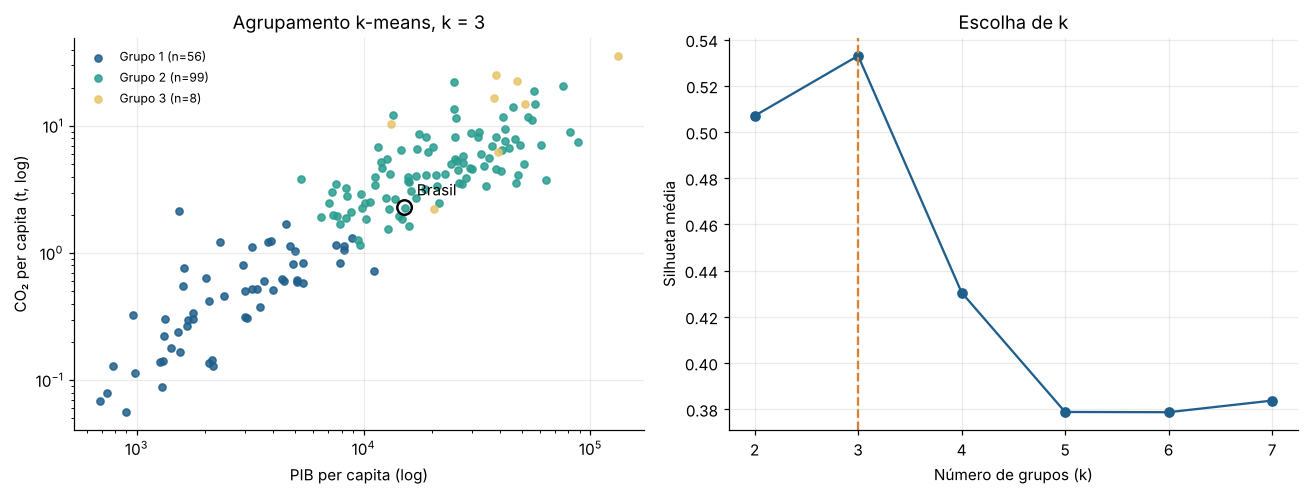

In [9]:
atrib_c = ['log_co2', 'log_pib', 'log_energia', 'metano']
print('Agrupamento: um corte (2022), um país por linha')
C = P[P['ano'] == ANO].set_index('iso_code').rename(columns={'metano_per_capita': 'metano'}).dropna(subset=atrib_c).copy()
Z = StandardScaler().fit_transform(C[atrib_c])
print('Países no agrupamento:', len(C))
sil = {}
for k in range(2, 8):
    km = KMeans(n_clusters=k, n_init=20, random_state=SEMENTE).fit(Z)
    sil[k] = float(silhouette_score(Z, km.labels_))
print({k: round(v, 3) for k, v in sil.items()})
k_ok = max((k for k in sil if 3 <= k <= 6), key=sil.get)      # regra fixada: melhor silhueta entre 3 e 6 grupos
km = KMeans(n_clusters=k_ok, n_init=20, random_state=SEMENTE).fit(Z)
C['grupo'] = km.labels_
perfil = C.groupby('grupo').agg(paises=('pais', 'size'), co2_pc=('co2_per_capita', 'median'),
                                pib_pc=('pib_per_capita', 'median'), energia_pc=('energia_per_capita', 'median'),
                                metano_pc=('metano', 'median')).round(2)
ordem = perfil['co2_pc'].sort_values().index
perfil = perfil.loc[ordem]; perfil.index = range(1, k_ok + 1)
C['grupo'] = C['grupo'].map({old: i + 1 for i, old in enumerate(ordem)})
print(f'\nk escolhido: {k_ok} (silhueta {sil[k_ok]:.3f})'); print(perfil.to_string())
gbr = int(C.loc['BRA', 'grupo']); print('Brasil está no grupo', gbr)
exemplos = {int(g): C[C.grupo == g].sort_values('populacao', ascending=False)['pais'].head(6).tolist() for g in range(1, k_ok + 1)}
for g, e in exemplos.items(): print(g, e)
R['agrupamento'] = {'n': int(len(C)), 'silhueta_por_k': sil, 'k': int(k_ok), 'perfil': perfil.reset_index().rename(columns={'index': 'grupo'}).to_dict('records'),
                    'grupo_brasil': gbr, 'maiores_paises_por_grupo': exemplos}
C[['pais', 'grupo', 'co2_per_capita', 'pib_per_capita', 'energia_per_capita', 'metano']].to_csv(TRATADOS / 'grupos_2022.csv')

# Complemento descritivo (a regra de escolha não muda): como ficaria com k = 4?
km4 = KMeans(n_clusters=4, n_init=20, random_state=SEMENTE).fit(Z)
C4 = C.assign(g4=km4.labels_)
p4 = C4.groupby('g4').agg(paises=('pais', 'size'), co2_pc=('co2_per_capita', 'median'), pib_pc=('pib_per_capita', 'median'),
                          energia_pc=('energia_per_capita', 'median'), metano_pc=('metano', 'median')).round(2).sort_values('co2_pc')
ordem4 = list(p4.index); p4.index = range(1, 5)
C4['g4'] = C4['g4'].map({o: i + 1 for i, o in enumerate(ordem4)})
print('\nDescritivo, k = 4 (silhueta %.3f):' % sil[4]); print(p4.to_string())
ex4 = {int(g): C4[C4.g4 == g].sort_values('populacao', ascending=False)['pais'].head(6).tolist() for g in range(1, 5)}
for g, e in ex4.items(): print(g, e)
print('Brasil no k=4: grupo', int(C4.loc['BRA', 'g4']))
R['agrupamento_k4_descritivo'] = {'silhueta': sil[4], 'perfil': p4.reset_index().rename(columns={'index': 'grupo'}).to_dict('records'),
                                  'maiores_paises_por_grupo': ex4, 'grupo_brasil': int(C4.loc['BRA', 'g4'])}

fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
cores = ['#1f5f8b', '#2a9d8f', '#e9c46a', '#d9822b', '#b5483a', '#6d597a'][:k_ok]
for g in range(1, k_ok + 1):
    s = C[C.grupo == g]
    ax[0].scatter(s['pib_per_capita'], s['co2_per_capita'], s=22, color=cores[g - 1], alpha=.85, label=f'Grupo {g} (n={len(s)})')
ax[0].scatter(C.loc['BRA', 'pib_per_capita'], C.loc['BRA', 'co2_per_capita'], s=90, facecolors='none', edgecolors='black', lw=1.6)
ax[0].annotate('Brasil', (C.loc['BRA', 'pib_per_capita'], C.loc['BRA', 'co2_per_capita']), xytext=(8, 8), textcoords='offset points')
ax[0].set_xscale('log'); ax[0].set_yscale('log'); ax[0].set_xlabel('PIB per capita (log)'); ax[0].set_ylabel('CO₂ per capita (t, log)')
ax[0].legend(fontsize=8, frameon=False); ax[0].set_title(f'Agrupamento k-means, k = {k_ok}')
ax[1].plot(list(sil), list(sil.values()), 'o-', color=AZUL); ax[1].axvline(k_ok, color=LARANJA, ls='--')
ax[1].set_xlabel('Número de grupos (k)'); ax[1].set_ylabel('Silhueta média'); ax[1].set_title('Escolha de k')
plt.tight_layout(); plt.savefig(FIGS / '04-agrupamento.png', dpi=130); plt.show()

**Resultado.** Com 163 países em 2022 (um corte, um país por linha) e quatro variáveis padronizadas, a silhueta média foi 0,507 (k=2), **0,533 (k=3)**, 0,430 (k=4), 0,379 (k=5 e k=6) e 0,384 (k=7). Pela regra fixada antes (melhor silhueta entre 3 e 6 grupos), k = 3:

| Grupo | Países | CO₂ per capita (mediana) | PIB per capita | Energia per capita | Metano per capita |
| --- | --- | --- | --- | --- | --- |
| 1 | 56 | 0,51 t | 2.680 | 2.027 kWh | 0,79 |
| 2 | 99 | 4,45 t | 20.783 | 23.846 kWh | 1,06 |
| 3 | 8 | 15,64 t | 38.707 | 76.570 kWh | 7,51 |

O Brasil está no grupo 2, junto com China, Índia, Estados Unidos, Rússia e Indonésia (os de maior população). O grupo 3 tem 8 países, entre eles Austrália, Nova Zelândia, Omã, Kuwait, Uruguai e Mongólia.

**Descritivo (k = 4, silhueta 0,430, não alterou a escolha).** Os grupos têm 34, 50, 71 e 8 países. O Brasil fica no grupo 3, com China, Estados Unidos, Rússia, México e Japão.

**Interpretação.**
- O k = 3 tem a melhor silhueta, mas ela vem sobretudo de separar 8 países extremos em energia e metano. O grupo 2 mistura 99 países muito diferentes.
- O k = 4 divide melhor a faixa do meio (1,70 t contra 5,65 t) e é mais útil para descrever, ainda que menos coeso.
- Uma silhueta de 0,53 indica estrutura moderada. Não há grupos "naturais" bem separados.

**Hipótese.** O grupo 3 junta dois perfis diferentes: países produtores de petróleo (energia alta) e países pecuaristas (metano alto). O agrupamento não distingue isso.

## Brasil no tempo, comparado ao mundo

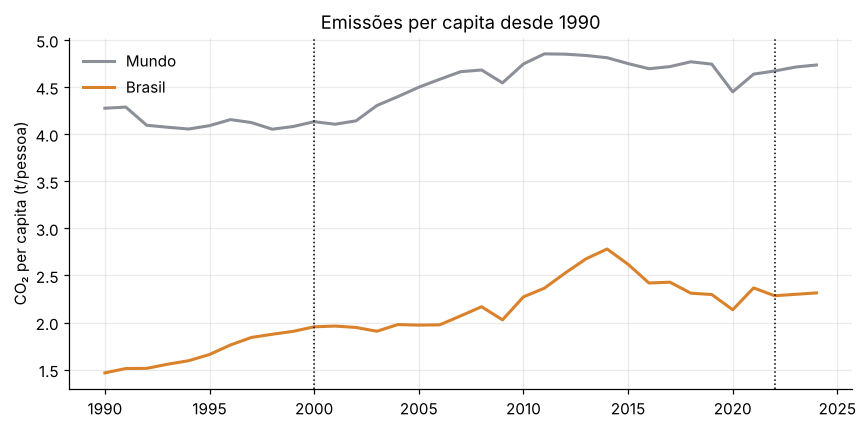

{'brasil_2000': 1.96, 'brasil_2022': 2.29, 'brasil_pico_ano': 2014, 'brasil_pico': 2.78, 'mundo_2000': 4.13, 'mundo_2022': 4.67, 'brasil_2012': 2.53, 'mundo_2012': 4.85, 'brasil_1990': 1.47, 'mundo_1990': 4.28}


In [10]:
def serie(nome):
    return paises[paises.country == nome].set_index('year')['co2_per_capita'] if nome != 'World' else \
        bruto[bruto.country == 'World'].set_index('year')['co2_per_capita']
s_br, s_mu = serie('Brazil'), serie('World')
fig, ax = plt.subplots(figsize=(8, 4))
for s, n, c in ((s_mu, 'Mundo', CINZA), (s_br, 'Brasil', LARANJA)):
    t = s.loc[1990:2024]; ax.plot(t.index, t.values, label=n, color=c, lw=2)
ax.axvline(ANO_INICIO_PAINEL, color='black', ls=':', lw=1); ax.axvline(ANO, color='black', ls=':', lw=1)
ax.set_ylabel('CO₂ per capita (t/pessoa)'); ax.set_title('Emissões per capita desde 1990'); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(FIGS / '05-brasil-mundo.png', dpi=130); plt.show()
R['brasil_mundo'] = {'brasil_2000': float(s_br.loc[2000]), 'brasil_2022': float(s_br.loc[2022]), 'brasil_pico_ano': int(s_br.loc[1990:2024].idxmax()), 'brasil_pico': float(s_br.loc[1990:2024].max()),
                     'mundo_2000': float(s_mu.loc[2000]), 'mundo_2022': float(s_mu.loc[2022]), 'brasil_2012': float(s_br.loc[2012]), 'mundo_2012': float(s_mu.loc[2012]),
                     'brasil_1990': float(s_br.loc[1990]), 'mundo_1990': float(s_mu.loc[1990])}
print({k: round(v, 2) for k, v in R['brasil_mundo'].items()})

**Resultado.** O CO₂ per capita do Brasil foi 1,47 t em 1990, 1,96 t em 2000, 2,53 t em 2012 (pico de 2,78 t em 2014) e 2,29 t em 2022. O do mundo foi 4,28 t, 4,13 t, 4,85 t e 4,67 t. Em 2022 o Brasil emitia cerca de metade da média mundial (0,49).

**Interpretação.** O Brasil subiu até 2014 e caiu depois. De 2012 a 2022 a queda foi de 9,6%, contra 3,7% do mundo. Essas emissões **não incluem mudança no uso da terra**, que no caso do Brasil é relevante e está fora desta análise.

## Registro dos resultados

In [11]:
with open(RESULT / 'resultados.json', 'w', encoding='utf-8') as f:
    json.dump(R, f, ensure_ascii=False, indent=2, default=float)
print('Gravado: resultados/resultados.json')

Gravado: resultados/resultados.json


## Conclusão

- **A:** com 3.772 linhas de 164 países, o PIB per capita sozinho prevê o CO₂ per capita com erro típico de cerca de ×1,65 na validação (R² 0,83). Incluir a energia per capita baixa o erro para ×1,23 no teste (R² 0,97), mas é uma relação quase mecânica.
- **B:** com 2.132 janelas de 10 anos, é possível acertar 78% das janelas em países que o modelo nunca viu (referência: 67%), com incerteza de vários pontos percentuais porque as janelas se sobrepõem.
- **C:** há três grupos pela silhueta, mas dois são pequenos ou heterogêneos. A estrutura é moderada.
- O Brasil emite menos do que o previsto para sua energia e seu PIB, em todos os 23 anos (hipótese: matriz elétrica renovável).
- **Limites:** só CO₂ de combustíveis e indústria (sem uso da terra); 164 países com PIB; um único sorteio de 41 países de teste; observações do mesmo país se repetem; associações, não causas.

**Fontes:** Our World in Data. *CO₂ and Greenhouse Gas Emissions* (dados em https://github.com/owid/co2-data, CC BY 4.0). Global Carbon Project; Energy Institute; Maddison Project Database. SCIKIT-LEARN. *User Guide*. https://scikit-learn.org/stable/user_guide.html.